In [ ]:

# Import Pandas
import pandas as pd

# Load the uploaded dataset
df = pd.read_csv('/content/customer_churn_sample(1).csv')

# Display the first 5 customers
df.head()


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes


In [ ]:

# Check number of rows and columns
df.shape


(15, 11)

In [ ]:

# Get dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        15 non-null     object 
 1   Gender            15 non-null     object 
 2   Age               15 non-null     int64  
 3   TenureMonths      15 non-null     int64  
 4   SubscriptionType  15 non-null     object 
 5   MonthlyCharges    15 non-null     float64
 6   TotalCharges      15 non-null     float64
 7   ContractType      15 non-null     object 
 8   SupportTickets    15 non-null     int64  
 9   PaymentMethod     15 non-null     object 
 10  Churn             15 non-null     object 
dtypes: float64(2), int64(3), object(6)
memory usage: 1.4+ KB


In [ ]:

# Statistical summary
df.describe()


,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportTickets
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,39.066667,18.800000,84.656667,2088.478667,2.533333
std,11.392144,14.333776,42.739521,2407.365767,1.922300
min,23.000000,2.000000,49.990000,99.980000,0.000000
25%,30.000000,7.000000,49.990000,449.910000,1.000000
50%,38.000000,15.000000,79.990000,1099.780000,2.000000
75%,47.000000,27.000000,114.990000,3209.730000,4.000000
max,60.000000,48.000000,149.990000,7199.520000,6.000000


In [3]:

# Import required libraries
import pandas as pd
from google.colab import files

# Upload the customer dataset
uploaded = files.upload()

# Automatically detect the uploaded filename
filename = next(iter(uploaded))

# Read the dataset
df = pd.read_csv(filename)

# Confirm successful loading
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())


Saving customer_churn_sample(1).csv to customer_churn_sample(1).csv
Dataset loaded successfully!
Dataset shape: (15, 11)

Missing values:
CustomerID          0
Gender              0
Age                 0
TenureMonths        0
SubscriptionType    0
MonthlyCharges      0
TotalCharges        0
ContractType        0
SupportTickets      0
PaymentMethod       0
Churn               0
dtype: int64


In [4]:

# Count customers who stayed and left
print(df['Churn'].value_counts())

# Calculate churn percentage
print("\nChurn percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)



Churn
No     8
Yes    7
Name: count, dtype: int64

Churn percentage:
Churn
No     53.333333
Yes    46.666667
Name: proportion, dtype: float64


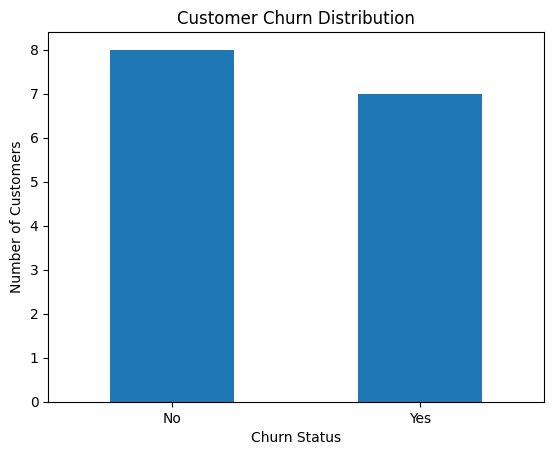

In [5]:

import matplotlib.pyplot as plt

# Count churn categories
churn_counts = df['Churn'].value_counts()

# Create bar chart
churn_counts.plot(kind='bar')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)

plt.show()


SubscriptionType
Basic         7
Pro           4
Enterprise    4
Name: count, dtype: int64


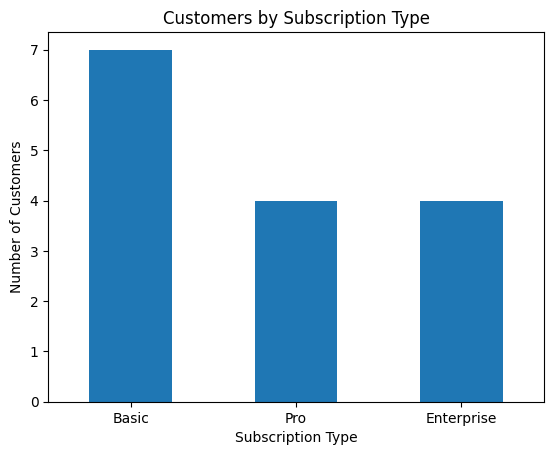

In [6]:

# Count subscription types
print(df['SubscriptionType'].value_counts())

# Visualize subscription types
df['SubscriptionType'].value_counts().plot(kind='bar')

plt.title('Customers by Subscription Type')
plt.xlabel('Subscription Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)

plt.show()


In [7]:

# Compare contract type with customer churn

contract_churn = pd.crosstab(
    df['ContractType'],
    df['Churn']
)

print(contract_churn)



Churn           No  Yes
ContractType           
Month-to-Month   0    7
One Year         4    0
Two Year         4    0


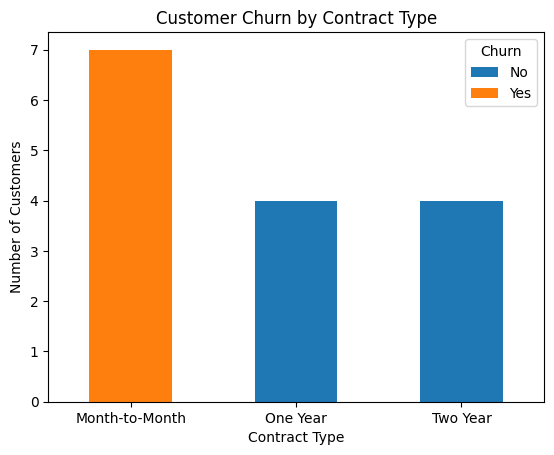

In [8]:

# Create a stacked bar chart

contract_churn.plot(kind='bar', stacked=True)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')

plt.show()


In [10]:

# Calculate average support tickets for churned and retained customers

support_analysis = df.groupby('Churn')['SupportTickets'].mean()

print(support_analysis)


Churn
No     1.000000
Yes    4.285714
Name: SupportTickets, dtype: float64


Churn
No     29.125
Yes     7.000
Name: TenureMonths, dtype: float64


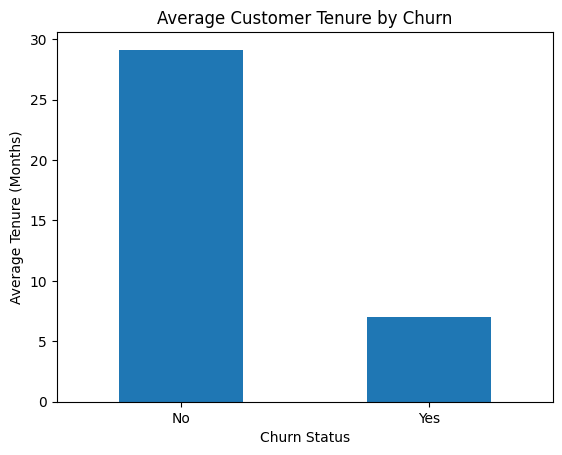

In [11]:

# Compare average tenure by churn status

tenure_analysis = df.groupby('Churn')['TenureMonths'].mean()

print(tenure_analysis)

# Create a chart
tenure_analysis.plot(kind='bar')

plt.title('Average Customer Tenure by Churn')
plt.xlabel('Churn Status')
plt.ylabel('Average Tenure (Months)')
plt.xticks(rotation=0)

plt.show()


Churn
No     107.490000
Yes     58.561429
Name: MonthlyCharges, dtype: float64


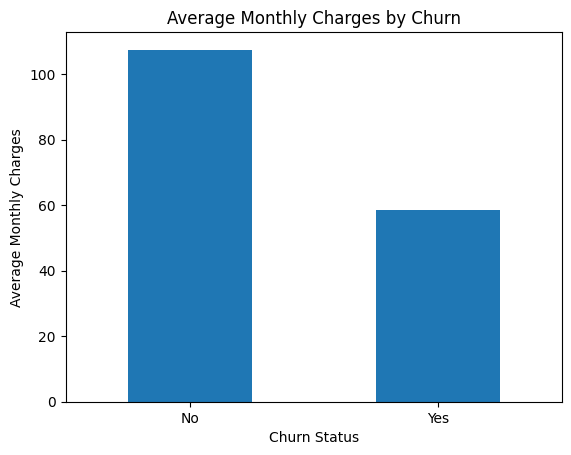

In [12]:

# Compare monthly charges by churn status

charges_analysis = df.groupby('Churn')['MonthlyCharges'].mean()

print(charges_analysis)

# Create a chart
charges_analysis.plot(kind='bar')

plt.title('Average Monthly Charges by Churn')
plt.xlabel('Churn Status')
plt.ylabel('Average Monthly Charges')
plt.xticks(rotation=0)

plt.show()


In [13]:

# Step 6: Customer Segmentation

def assign_segment(row):

    # Segment 1: At-Risk Customers
    if (row['ContractType'] == 'Month-to-Month'
        or row['SupportTickets'] >= 4
        or row['TenureMonths'] <= 6):
        return 'At-Risk'

    # Segment 2: High-Charge Customers
    elif row['MonthlyCharges'] >= 100:
        return 'High-Charge'

    # Segment 3: Loyal Customers
    elif row['TenureMonths'] >= 24:
        return 'Loyal'

    # Segment 4: Regular Customers
    else:
        return 'Regular'


# Apply segmentation to every customer
df['CustomerSegment'] = df.apply(assign_segment, axis=1)

# Display customer segments
print(df[['CustomerID', 'CustomerSegment', 'Churn']])

# Count customers in each segment
print("\nSegment Distribution:")
print(df['CustomerSegment'].value_counts())


   CustomerID CustomerSegment Churn
0   CUST-1001         At-Risk   Yes
1   CUST-1002           Loyal    No
2   CUST-1003         At-Risk   Yes
3   CUST-1004     High-Charge    No
4   CUST-1005         At-Risk   Yes
5   CUST-1006         Regular    No
6   CUST-1007         At-Risk   Yes
7   CUST-1008     High-Charge    No
8   CUST-1009         Regular    No
9   CUST-1010         At-Risk   Yes
10  CUST-1011     High-Charge    No
11  CUST-1012         At-Risk   Yes
12  CUST-1013         Regular    No
13  CUST-1014         At-Risk   Yes
14  CUST-1015     High-Charge    No

Segment Distribution:
CustomerSegment
At-Risk        7
High-Charge    4
Regular        3
Loyal          1
Name: count, dtype: int64


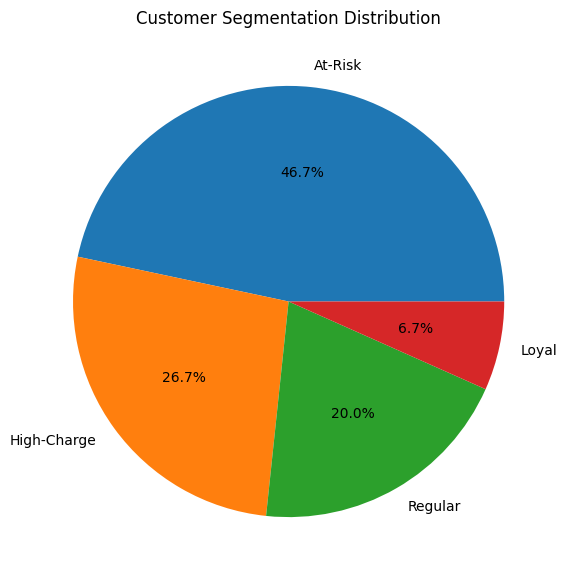

In [14]:

# Visualize customer segments

segment_counts = df['CustomerSegment'].value_counts()

segment_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7, 7)
)

plt.title('Customer Segmentation Distribution')
plt.ylabel('')

plt.show()


In [15]:

# Compare customer segments with actual churn

segment_churn = pd.crosstab(
    df['CustomerSegment'],
    df['Churn']
)

print(segment_churn)


Churn            No  Yes
CustomerSegment         
At-Risk           0    7
High-Charge       4    0
Loyal             1    0
Regular           3    0


In [16]:

# Step 7: Create Churn Risk Scoring System

def calculate_risk(row):

    score = 0

    # Rule 1: Contract type
    if row['ContractType'] == 'Month-to-Month':
        score += 3

    # Rule 2: Customer tenure
    if row['TenureMonths'] <= 6:
        score += 3

    # Rule 3: Support tickets
    if row['SupportTickets'] >= 4:
        score += 2

    # Rule 4: Monthly charges
    if row['MonthlyCharges'] >= 100:
        score += 1

    return score


# Calculate risk score for every customer
df['RiskScore'] = df.apply(calculate_risk, axis=1)


# Assign risk category
def risk_category(score):

    if score <= 2:
        return 'Low Risk'

    elif score <= 5:
        return 'Medium Risk'

    else:
        return 'High Risk'


df['RiskCategory'] = df['RiskScore'].apply(risk_category)


# Display results
print(df[['CustomerID', 'RiskScore', 'RiskCategory']])


   CustomerID  RiskScore RiskCategory
0   CUST-1001          3  Medium Risk
1   CUST-1002          0     Low Risk
2   CUST-1003          8    High Risk
3   CUST-1004          1     Low Risk
4   CUST-1005          5  Medium Risk
5   CUST-1006          0     Low Risk
6   CUST-1007          8    High Risk
7   CUST-1008          1     Low Risk
8   CUST-1009          0     Low Risk
9   CUST-1010          8    High Risk
10  CUST-1011          1     Low Risk
11  CUST-1012          3  Medium Risk
12  CUST-1013          0     Low Risk
13  CUST-1014          8    High Risk
14  CUST-1015          1     Low Risk


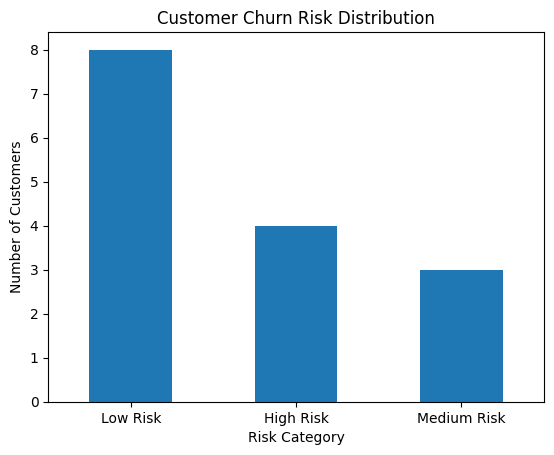

In [18]:

# Visualize customer risk categories

risk_counts.plot(kind='bar')

plt.title('Customer Churn Risk Distribution')
plt.xlabel('Risk Category')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)

plt.show()


In [19]:

# Final customer analysis table

final_table = df[[
    'CustomerID',
    'ContractType',
    'TenureMonths',
    'SupportTickets',
    'MonthlyCharges',
    'CustomerSegment',
    'RiskScore',
    'RiskCategory',
    'Churn'
]]

display(final_table)


,CustomerID,ContractType,TenureMonths,SupportTickets,MonthlyCharges,CustomerSegment,RiskScore,RiskCategory,Churn
0,CUST-1001,Month-to-Month,12,3,49.99,At-Risk,3,Medium Risk,Yes
1,CUST-1002,One Year,24,1,79.99,Loyal,0,Low Risk,No
2,CUST-1003,Month-to-Month,6,5,49.99,At-Risk,8,High Risk,Yes
3,CUST-1004,Two Year,36,0,149.99,High-Charge,1,Low Risk,No
4,CUST-1005,Month-to-Month,8,4,79.99,At-Risk,5,Medium Risk,Yes
5,CUST-1006,One Year,18,2,49.99,Regular,0,Low Risk,No
6,CUST-1007,Month-to-Month,3,6,49.99,At-Risk,8,High Risk,Yes
7,CUST-1008,Two Year,48,1,149.99,High-Charge,1,Low Risk,No
8,CUST-1009,One Year,15,2,79.99,Regular,0,Low Risk,No
9,CUST-1010,Month-to-Month,4,4,49.99,At-Risk,8,High Risk,Yes


In [20]:

# Step 8: Edge Case Testing

test_customers = pd.DataFrame([
    {
        'CustomerID': 'TEST01',
        'ContractType': 'One Year',
        'TenureMonths': 24,
        'SupportTickets': 0,
        'MonthlyCharges': 50
    },
    {
        'CustomerID': 'TEST02',
        'ContractType': 'Month-to-Month',
        'TenureMonths': 6,
        'SupportTickets': 4,
        'MonthlyCharges': 100
    },
    {
        'CustomerID': 'TEST03',
        'ContractType': 'Two Year',
        'TenureMonths': 12,
        'SupportTickets': 2,
        'MonthlyCharges': 80
    }
])

# Calculate scores
test_customers['RiskScore'] = test_customers.apply(
    calculate_risk, axis=1
)

# Assign risk categories
test_customers['RiskCategory'] = (
    test_customers['RiskScore'].apply(risk_category)
)

display(test_customers)


,CustomerID,ContractType,TenureMonths,SupportTickets,MonthlyCharges,RiskScore,RiskCategory
0,TEST01,One Year,24,0,50,0,Low Risk
1,TEST02,Month-to-Month,6,4,100,9,High Risk
2,TEST03,Two Year,12,2,80,0,Low Risk


In [21]:

# Compare risk category with actual churn

validation_table = pd.crosstab(
    df['RiskCategory'],
    df['Churn']
)

print("Risk Category vs Actual Churn:")
display(validation_table)


Risk Category vs Actual Churn:


Churn,No,Yes
RiskCategory,,
High Risk,0,4
Low Risk,8,0
Medium Risk,0,3


In [22]:

# Calculate churn rate for each risk category

risk_churn_rate = df.groupby('RiskCategory')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print("Churn Rate by Risk Category (%):")
print(risk_churn_rate)


Churn Rate by Risk Category (%):
RiskCategory
High Risk      100.0
Low Risk         0.0
Medium Risk    100.0
Name: Churn, dtype: float64


In [23]:

# Step 9: Create Retention Recommendations

def recommend_action(segment):

    if segment == 'At-Risk':
        return 'Contact customer and resolve service issues'

    elif segment == 'High-Charge':
        return 'Offer personalized plans and benefits'

    elif segment == 'Loyal':
        return 'Provide loyalty rewards'

    else:
        return 'Maintain engagement with regular offers'


# Generate recommendations
df['Recommendation'] = df['CustomerSegment'].apply(
    recommend_action
)

# Display final recommendations
display(df[[
    'CustomerID',
    'CustomerSegment',
    'RiskScore',
    'RiskCategory',
    'Recommendation'
]])


,CustomerID,CustomerSegment,RiskScore,RiskCategory,Recommendation
0,CUST-1001,At-Risk,3,Medium Risk,Contact customer and resolve service issues
1,CUST-1002,Loyal,0,Low Risk,Provide loyalty rewards
2,CUST-1003,At-Risk,8,High Risk,Contact customer and resolve service issues
3,CUST-1004,High-Charge,1,Low Risk,Offer personalized plans and benefits
4,CUST-1005,At-Risk,5,Medium Risk,Contact customer and resolve service issues
5,CUST-1006,Regular,0,Low Risk,Maintain engagement with regular offers
6,CUST-1007,At-Risk,8,High Risk,Contact customer and resolve service issues
7,CUST-1008,High-Charge,1,Low Risk,Offer personalized plans and benefits
8,CUST-1009,Regular,0,Low Risk,Maintain engagement with regular offers
9,CUST-1010,At-Risk,8,High Risk,Contact customer and resolve service issues


In [24]:
display(test_customers)


,CustomerID,ContractType,TenureMonths,SupportTickets,MonthlyCharges,RiskScore,RiskCategory
0,TEST01,One Year,24,0,50,0,Low Risk
1,TEST02,Month-to-Month,6,4,100,9,High Risk
2,TEST03,Two Year,12,2,80,0,Low Risk


In [25]:
display(validation_table)


Churn,No,Yes
RiskCategory,,
High Risk,0,4
Low Risk,8,0
Medium Risk,0,3
